<a href="https://colab.research.google.com/github/raimaravi13-netizen/Raima-file/blob/main/Newyork.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [3]:
from google.colab import files
uploaded = files.upload()

Saving AB_NYC_2019[1].csv to AB_NYC_2019[1].csv


In [5]:
df=pd.read_csv('/content/AB_NYC_2019[1].csv')

In [6]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [14]:
df.tail()

,neighbourhood_group,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
48890,Brooklyn,40.67853,-73.94995,Private room,70,2,0,0.0,2,9
48891,Brooklyn,40.70184,-73.93317,Private room,40,4,0,0.0,2,36
48892,Manhattan,40.81475,-73.94867,Entire home/apt,115,10,0,0.0,1,27
48893,Manhattan,40.75751,-73.99112,Shared room,55,1,0,0.0,6,2
48894,Manhattan,40.76404,-73.98933,Private room,90,7,0,0.0,1,23


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 10 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   neighbourhood_group             48895 non-null  object 
 1   latitude                        48895 non-null  float64
 2   longitude                       48895 non-null  float64
 3   room_type                       48895 non-null  object 
 4   price                           48895 non-null  int64  
 5   minimum_nights                  48895 non-null  int64  
 6   number_of_reviews               48895 non-null  int64  
 7   reviews_per_month               48895 non-null  float64
 8   calculated_host_listings_count  48895 non-null  int64  
 9   availability_365                48895 non-null  int64  
dtypes: float64(3), int64(5), object(2)
memory usage: 3.7+ MB


In [16]:
df.duplicated().sum()

np.int64(0)

In [17]:
df.isnull().sum()

,0
neighbourhood_group,0
latitude,0
longitude,0
room_type,0
price,0
minimum_nights,0
number_of_reviews,0
reviews_per_month,0
calculated_host_listings_count,0
availability_365,0


In [7]:
print("Shape of dataset:", df.shape)

print("\nColumns:")
print(df.columns)

print("\nData types:")
print(df.dtypes)

Shape of dataset: (48895, 16)

Columns:
Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')

Data types:
id                                  int64
name                               object
host_id                             int64
host_name                          object
neighbourhood_group                object
neighbourhood                      object
latitude                          float64
longitude                         float64
room_type                          object
price                               int64
minimum_nights                      int64
number_of_reviews                   int64
last_review                        object
reviews_per_month                 float64
calculated_host_listings_count      int64
avail

In [8]:
numerical_columns = df.select_dtypes(include=np.number).columns
categorical_columns = df.select_dtypes(include='object').columns

print("Numerical columns:")
print(list(numerical_columns))

print("\nCategorical columns:")
print(list(categorical_columns))

Numerical columns:
['id', 'host_id', 'latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']

Categorical columns:
['name', 'host_name', 'neighbourhood_group', 'neighbourhood', 'room_type', 'last_review']


In [9]:
missing_count = df.isnull().sum()
missing_percentage = (missing_count / len(df)) * 100

missing_data = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing Percentage': missing_percentage
})

print(missing_data[missing_data['Missing Count'] > 0])

                   Missing Count  Missing Percentage
name                          16            0.032723
host_name                     21            0.042949
last_review                10052           20.558339
reviews_per_month          10052           20.558339


In [10]:
print(df[df['number_of_reviews'] == 0][
    ['number_of_reviews', 'reviews_per_month']
].head(20))

     number_of_reviews  reviews_per_month
2                    0                NaN
19                   0                NaN
26                   0                NaN
36                   0                NaN
38                   0                NaN
193                  0                NaN
204                  0                NaN
260                  0                NaN
265                  0                NaN
267                  0                NaN
276                  0                NaN
345                  0                NaN
349                  0                NaN
390                  0                NaN
425                  0                NaN
432                  0                NaN
437                  0                NaN
486                  0                NaN
545                  0                NaN
585                  0                NaN


In [11]:
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)

In [12]:
df = df.drop('last_review', axis=1)

In [13]:
df = df.drop([
    'id',
    'name',
    'host_id',
    'host_name',
    'neighbourhood'
], axis=1)

print(df.columns)

Index(['neighbourhood_group', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'reviews_per_month',
       'calculated_host_listings_count', 'availability_365'],
      dtype='object')


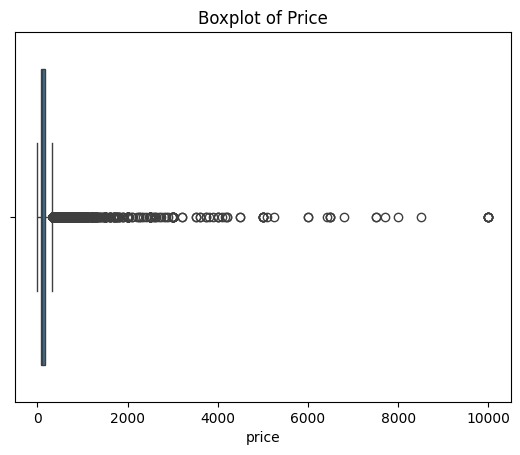

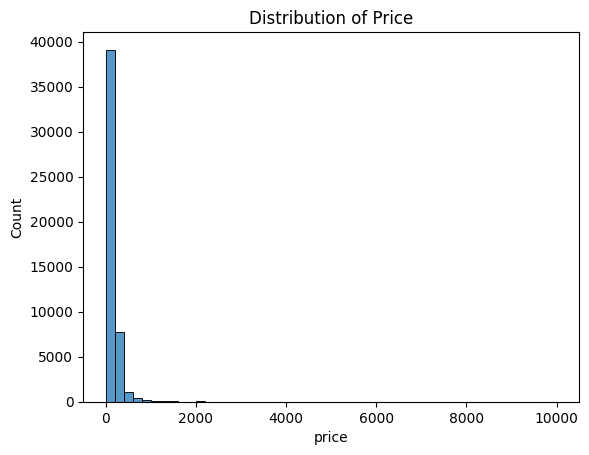

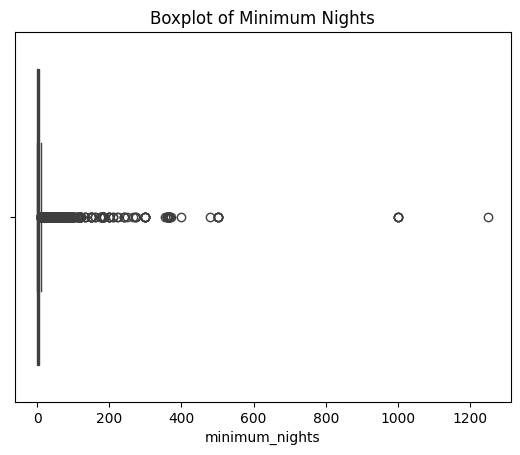

In [18]:

sns.boxplot(x=df['price'])
plt.title('Boxplot of Price')
plt.show()


sns.histplot(df['price'], bins=50)
plt.title('Distribution of Price')
plt.show()


sns.boxplot(x=df['minimum_nights'])
plt.title('Boxplot of Minimum Nights')
plt.show()

In [19]:
price_limit = df['price'].quantile(0.95)
minimum_nights_limit = df['minimum_nights'].quantile(0.95)

print("95th percentile of price:", price_limit)
print("95th percentile of minimum_nights:", minimum_nights_limit)

df = df[
    (df['price'] <= price_limit) &
    (df['minimum_nights'] <= minimum_nights_limit)
]

print("New shape:", df.shape)

95th percentile of price: 355.0
95th percentile of minimum_nights: 30.0
New shape: (45759, 10)


In [20]:
df = pd.get_dummies(
    df,
    columns=['neighbourhood_group', 'room_type'],
    drop_first=True
)

print(df.head())
print(df.dtypes)

   latitude  longitude  price  minimum_nights  number_of_reviews  \
0  40.64749  -73.97237    149               1                  9   
1  40.75362  -73.98377    225               1                 45   
2  40.80902  -73.94190    150               3                  0   
3  40.68514  -73.95976     89               1                270   
4  40.79851  -73.94399     80              10                  9   

   reviews_per_month  calculated_host_listings_count  availability_365  \
0               0.21                               6               365   
1               0.38                               2               355   
2               0.00                               1               365   
3               4.64                               1               194   
4               0.10                               1                 0   

   neighbourhood_group_Brooklyn  neighbourhood_group_Manhattan  \
0                          True                          False   
1             

In [21]:
X = df.drop('price', axis=1)
y = df['price']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (45759, 13)
y shape: (45759,)


In [22]:
X = X.astype(int)

print(X.head())

   latitude  longitude  minimum_nights  number_of_reviews  reviews_per_month  \
0        40        -73               1                  9                  0   
1        40        -73               1                 45                  0   
2        40        -73               3                  0                  0   
3        40        -73               1                270                  4   
4        40        -73              10                  9                  0   

   calculated_host_listings_count  availability_365  \
0                               6               365   
1                               2               355   
2                               1               365   
3                               1               194   
4                               1                 0   

   neighbourhood_group_Brooklyn  neighbourhood_group_Manhattan  \
0                             1                              0   
1                             0                         

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (36607, 13)
Testing data: (9152, 13)


In [24]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [25]:
y_pred = model.predict(X_test)

print("First 10 predictions:")
print(y_pred[:10])

First 10 predictions:
[163.92296201 158.37933325 170.93253912 181.12898593 180.84472508
 179.5066381  153.03687888  55.37703236 191.26385715  91.60502704]


In [26]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("R² Score:", r2)
print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)

R² Score: 0.4548271371208843
Mean Absolute Error (MAE): 39.053742926924684
Mean Squared Error (MSE): 2920.6801318990624
Root Mean Squared Error (RMSE): 54.043317180749206


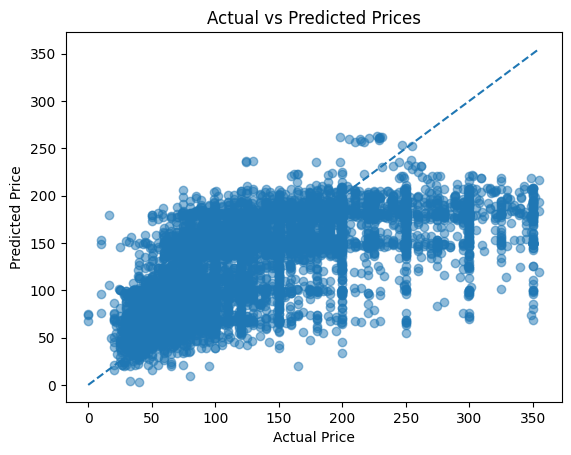

In [27]:


plt.scatter(y_test, y_pred, alpha=0.5)

# Perfect prediction line
minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle='--'
)

plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted Prices')

plt.show()

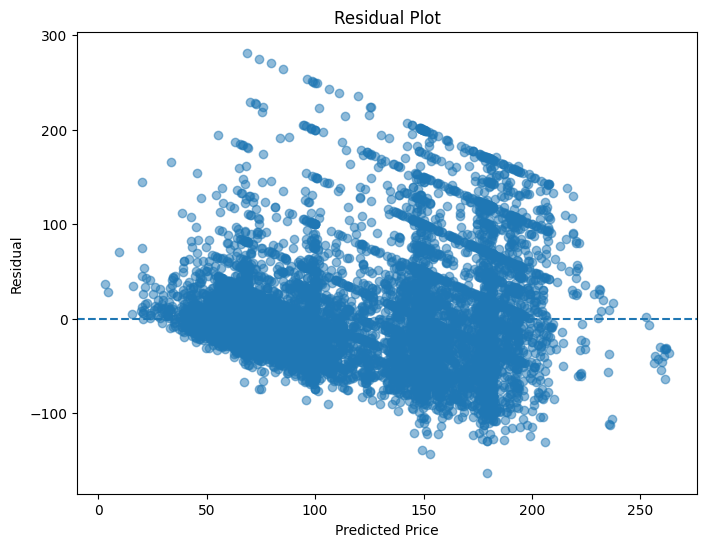

In [28]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 6))

plt.scatter(y_pred, residuals, alpha=0.5)

plt.axhline(y=0, linestyle='--')

plt.xlabel('Predicted Price')
plt.ylabel('Residual')
plt.title('Residual Plot')

plt.show()

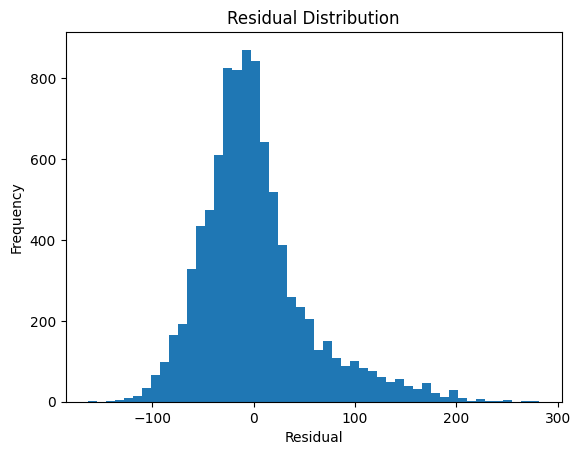

In [29]:


plt.hist(residuals, bins=50)

plt.xlabel('Residual')
plt.ylabel('Frequency')
plt.title('Residual Distribution')

plt.show()